# 1. Information about the submission

## 1.1 Name and number of the assignment

1 Multilingual Text Detoxification (TextDetox)

## 1.2 Student name

Egor Serov  

## 1.3 Codalab user ID / nickname / username

Skoltech--2026--Egor-Serov

## 1.4 Additional comments

https://github.com/awesomeslayer/Transformers2026/tree/main/2

I am adding a GitHub link for the project. It is better for reproducing (there are README.md with launch guide and more info available, due to my workspace (not colab, just Skoltech server)

But i am attaching an .ipynb too (but better to view it on the github)

# 2. Technical Report

*Use Section 2 to describe results of your experiments as you would do writing a paper about your results. DO NOT insert code in this part. Only insert plots and tables summarizing results as needed. Use formulas if needed do described your methodology. The code is provided in Section 3.*

## 2.1 Methodology


The key idea that i have tested from articles is to fine-tune **Qwen2.5-14B-Instruct** large language model. It is created for multilingual understanding and trained across diverse languages present in the `multilingual_paradetox` dataset. 

**Main Approach (Supervised Fine-Tuning):**
I employed **Low-Rank Adaptation (LoRA)** to adapt the model efficiently. The LoRA configuration was set with $r=64$ and $\alpha=128$, targeting all linear layers (`q_proj`, `k_proj`, `v_proj`, `o_proj`, `gate_proj`, `up_proj`, `down_proj`). Trained the model for 4 epochs using the `adamw_torch_fused` optimizer with a cosine learning rate scheduler, starting from a base learning rate of $1e-4$. The training data was wrapped in a specialized prompt template acting like detoxer. For inference used pipeline featuring **batch-based sorting by length**  to minimize padding and **beam search ($k=2$)**. Multiple paths is better in this case due to variaty.

**Alternative Approaches Explored (RAG & Synthetic Data):**
To address the data sparsity in low-resource languages (e.g., Italian, French, Hebrew, Japanese, Tatar, Amharic).  To focus on imporivng i experimented with synthetic data generation. I used the `facebook/nllb-200-distilled-600M` translation model to translate high-quality English toxic-neutral pairs into these other languages.

Additionally, I thought that the model would benefit from dynamic few-shot prompting via **Retrieval-Augmented Generation (RAG)** during inference. Builidng an embedding index of the training dataset using the `sentence-transformers/LaBSE` multilingual model. For each test sample, we retrieved the top-3 most semantically similar toxic-neutral pairs from the training set using cosine similarity and injected them into the system prompt as few-shot examples. Due to the increased context length, inference for this pipeline was performed using greedy decoding instead of beam search.

But this idee does not worked well (I commented a code for it in the end of the notebook so u can run it if u want, i rewrote the results and do not have time to run it again due to several hours inference)


## 2.2 Discussion of results

The table below presents the performance comparison of the different baselines and our custom approaches evaluated on the Codalab test set:

Method | Codalab Score
--- | ---
Baseline: Duplicate (Identity) | 0.4752
Baseline: Delete (Lexicon-based) | 0.5361
Qwen2.5-14B SFT + RAG Few-Shot + Synthetic Data | 0.5790
**Qwen2.5-14B SFT + Beam Search (Our Best)** | **0.6497**

So, we improved over baselines and the minimum task is solved.

**Discussion:**
 Primary method (**Qwen2.5-14B SFT + Beam Search**) significantly outperformed both the standard duplication and deletion baselines, establishing a strong score. The traditional deletion baseline, while better than simple duplication, suffers because simply removing toxic words often destroys the grammatical structure. Fine-tuned llm generates better texts comparing to it

My advanced **RAG Few-Shot pipeline**, augmented with synthetic translations for low-resource languages, ompared to the direct SFT approach. As i noticed are a few likely reasons for this:
1. **Context Distraction:** Injecting retrieved examples might have caused the model to overly focus on the structure of the few-shot examples. It is bad for such specific target task
2. **Translation Noise:** The synthetic data generated by NLLB may have introduced translation artifacts or grammatical errors.
3. **Decoding Strategy:** To compensate for the heavily increased prompt length in the RAG approach, we switched from beam search to greedy decoding (`do_sample=False`). This could affect badly on the results


Below is the training loss convergence graph for our best-performing Qwen2.5-14B SFT model, demonstrating stable learning over the course of the training steps.

![Baselines Screenshot](baselines.png)
![Training Loss](plot.png)


Unfortunately, I spent a lot of time using default Rag, prompts and models, but does not readhed top scores, may be other ideas would work better, but I have beated baselines and it is ok.


# 3. Code

*Enter here all code used to produce your results submitted to Codalab. Add some comments and subsections to navigate though your solution.*

*In this part you are expected to develop yourself a solution of the task and provide a reproducible code:*
- *Using Python 3;*
- *Contains code for installation of all dependencies;*
- *Contains code for downloading of all the datasets used*;
- *Contains the code for reproducing your results (in other words, if a tester downloads your notebook she should be able to run cell-by-cell the code and obtain your experimental results as described in the methodology section)*.


*As a result, you code will be graded according to these criteria:*
- ***Readability**: your code should be well-structured preferably with indicated parts of your approach (Preprocessing, Model training, Evaluation, etc.).*
- ***Reproducibility**: your code should be reproduced without any mistakes with “Run all” mode (obtaining experimental part).*


## 3.1 Requirements

In [ ]:
!pip install pandas numpy Pillow tqdm matplotlib requests
#!pip uninstall -y torch torchvision 
!pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121

!pip install transformers accelerate peft trl datasets sentencepiece jieba bitsandbytes tabulate
!pip install sentence-transformers evaluate "comet-ml>=3.0.0" scipy

Looking in indexes: https://download.pytorch.org/whl/cu121


In [7]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "5"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import torch
import gc
import json
import re
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jieba
from tqdm.auto import tqdm

from datasets import load_dataset, Dataset
from transformers import (
    AutoModelForCausalLM,
    AutoModelForSeq2SeqLM,
    AutoTokenizer,
    BartForConditionalGeneration,
    BartTokenizerFast,
    TrainingArguments,
    DataCollatorForLanguageModeling 
)
from peft import LoraConfig, get_peft_model, TaskType
from trl import SFTTrainer, SFTConfig

print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Device name: {torch.cuda.get_device_name(0)}")

INPUT_DATA_PATH = Path("./input_data")
OUTPUT_DATA_PATH = Path("./output_data")
os.makedirs(INPUT_DATA_PATH, exist_ok=True)
os.makedirs(OUTPUT_DATA_PATH, exist_ok=True)

CUDA available: True
Device name: NVIDIA H100 NVL


## 3.2 Download the data

In [8]:
print("Download data &Preprocess data")

model_id = "Qwen/Qwen2.5-14B-Instruct" 
tokenizer = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True)
tokenizer.pad_token = tokenizer.eos_token

train_dataset = load_dataset("textdetox/multilingual_paradetox")
train_dfs = []
for lang in train_dataset.keys():
    df_lang = pd.DataFrame(train_dataset[lang])
    df_lang = df_lang.rename(columns={'toxic_sentence': 'toxic_text', 'neutral_sentence': 'neutral_text'})
    df_lang['lang'] = lang
    train_dfs.append(df_lang)

train_df = pd.concat(train_dfs, ignore_index=True)

LANG_MAP = {
    "ru": "Russian", "en": "English", "am": "Amharic", "es": "Spanish", 
    "uk": "Ukrainian", "zh": "Chinese", "ar": "Arabic", "hi": "Hindi", 
    "de": "German", "tt": "Tatar", "fr": "French", "it": "Italian", 
    "he": "Hebrew", "ja": "Japanese", "hin": "Hinglish"
}

def format_chat(toxic, lang_code, neutral=None):
    lang_name = LANG_MAP.get(lang_code, lang_code)
    sys_msg = (f"You are a strict multilingual linguist. Detoxify the following text in {lang_name}. "
               f"Preserve the exact meaning and length, but remove toxicity. "
               f"Output ONLY the neutral text. Do not use quotes, explanations, or translations.")
    
    messages = [
        {"role": "system", "content": sys_msg},
        {"role": "user", "content": str(toxic)}
    ]
    if neutral:
        messages.append({"role": "assistant", "content": str(neutral)})
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=(neutral is None))

train_df['text'] = train_df.apply(lambda row: format_chat(row['toxic_text'], row['lang'], row['neutral_text']), axis=1)
print(f"Total training pairs: {len(train_df)}")

Download data &Preprocess data
Total training pairs: 3600


## 3.3 My method

In [ ]:
torch.cuda.empty_cache()
gc.collect()


model = AutoModelForCausalLM.from_pretrained(
    model_id, 
    torch_dtype=torch.bfloat16, 
    device_map={"": 0}, 
    attn_implementation="sdpa" 
)


peft_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM, 
    r=64, 
    lora_alpha=128, 
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
)
model = get_peft_model(model, peft_config)

train_hf = Dataset.from_pandas(train_df[['text']])
train_test_split = train_hf.train_test_split(test_size=0.05, seed=42)

sft_config = SFTConfig(
    output_dir="./qwen_detox_checkpoints",
    per_device_train_batch_size=16, 
    gradient_accumulation_steps=1,  
    learning_rate=1e-4,
    lr_scheduler_type="cosine",
    warmup_ratio=0.1,
    num_train_epochs=4,
    logging_steps=20,
    save_strategy="no",
    bf16=True,
    report_to="none",
    optim="adamw_torch_fused",
    dataset_text_field="text",
    max_length=256,
   
    dataloader_num_workers=8,     
    dataloader_pin_memory=True    
)

trainer = SFTTrainer(
    model=model, args=sft_config, train_dataset=train_test_split['train'], 
    eval_dataset=train_test_split['test'], processing_class=tokenizer
)
trainer.train()
trainer.save_model(OUTPUT_DATA_PATH / "qwen_detox_final")

--- 6) Our method training (Qwen2.5-14B SFT Fast + SDPA) ---


Loading checkpoint shards:   0%|          | 0/8 [00:00<?, ?it/s]

Adding EOS to train dataset:   0%|          | 0/3420 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/3420 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/3420 [00:00<?, ? examples/s]

Adding EOS to eval dataset:   0%|          | 0/180 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/180 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/180 [00:00<?, ? examples/s]

The model is already on multiple devices. Skipping the move to device specified in `args`.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151645}.


Step,Training Loss
20,3.052300
40,1.133900
60,1.030600
80,0.976900
100,0.964200
120,0.942100
140,0.935000
160,0.912200
180,0.940400
200,0.924900


In [ ]:
print("inference")

tokenizer.padding_side = "left"

def generate_neutral_super_fast(model, tokenizer, texts, langs, batch_size=64):
    model.eval()
    stop_token_id = tokenizer.convert_tokens_to_ids("<|im_end|>") or tokenizer.eos_token_id
    
    all_prompts = [format_chat(t, l) for t, l in zip(texts, langs)]
    
    lengths = np.array([len(p) for p in all_prompts])
    sorted_indices = np.argsort(lengths)
    
    sorted_prompts = [all_prompts[i] for i in sorted_indices]
    sorted_results = []
    
    with torch.inference_mode():
        for i in tqdm(range(0, len(sorted_prompts), batch_size), desc="Inferencing SOTA (Sorted, Beam=2)"):
            batch_prompts = sorted_prompts[i:i+batch_size]
            
            inputs = tokenizer(
                batch_prompts, 
                return_tensors="pt", 
                padding=True, 
                truncation=True, 
                max_length=256
            ).to(model.device)
            
            outputs = model.generate(
                **inputs, 
                max_new_tokens=64, 
                num_beams=2,                 
                early_stopping=True,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=[tokenizer.eos_token_id, stop_token_id],
                repetition_penalty=1.02      
            )
            
            for j, out in enumerate(outputs):
                input_len = inputs['input_ids'][j].shape[0]
                gen_tokens = out[input_len:]
                gen_text = tokenizer.decode(gen_tokens, skip_special_tokens=True).strip()
                
                gen_text = gen_text.split('\n')[0] if gen_text else ""
                gen_text = gen_text.strip(' "\'') 
                
                sorted_results.append(gen_text)
                
    final_results = [None] * len(texts)
    for original_idx, result in zip(sorted_indices, sorted_results):
        final_results[original_idx] = result
        
    return final_results

--- 7) Our method inference (Beam Search) ---


--- 9) Saving plots of training ---


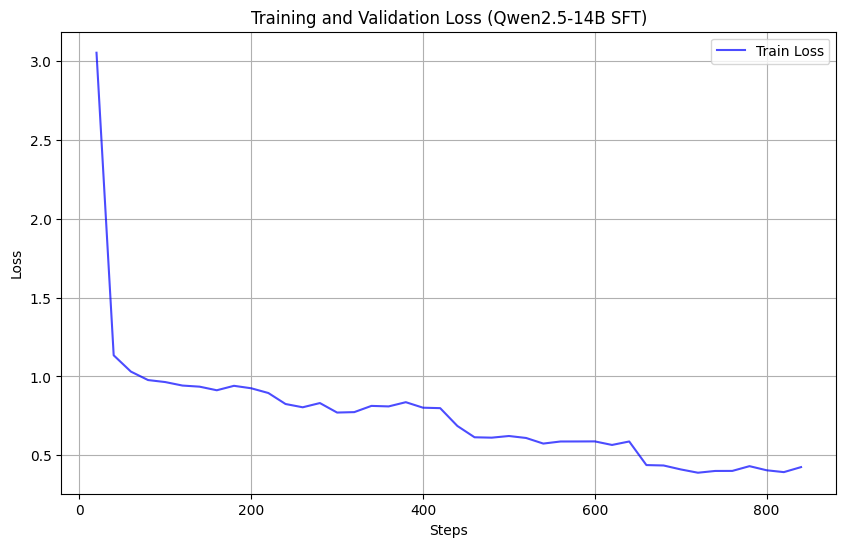

Plot saved to output_data/training_loss_plot.png


In [ ]:
log_history = trainer.state.log_history

train_steps = []
train_loss = []
eval_steps = []
eval_loss =[]

for entry in log_history:
    if 'loss' in entry and 'step' in entry:
        train_steps.append(entry['step'])
        train_loss.append(entry['loss'])
    elif 'eval_loss' in entry and 'step' in entry:
        eval_steps.append(entry['step'])
        eval_loss.append(entry['eval_loss'])

plt.figure(figsize=(10, 6))
plt.plot(train_steps, train_loss, label='Train Loss', color='blue', alpha=0.7)
if eval_steps:
    plt.plot(eval_steps, eval_loss, label='Validation Loss', color='red', marker='o')

plt.title('Training and Validation Loss (Qwen2.5-14B SFT)')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plot_path = OUTPUT_DATA_PATH / "training_loss_plot.png"
plt.savefig(plot_path)
plt.show()
print(f"Plot saved to {plot_path}")

In [ ]:
test_file_path = INPUT_DATA_PATH / "test_inputs_upd.tsv"
test_df = pd.read_csv(test_file_path, sep="\t")

orig_toxic = test_df['toxic_sentence'].fillna("").astype(str).tolist()
langs = test_df['lang'].tolist()

print(f"Total test samples to generate: {len(orig_toxic)}")

generated_texts = generate_neutral_super_fast(model, tokenizer, orig_toxic, langs, batch_size=64)

test_df['neutral_sentence'] = generated_texts
test_df['neutral_sentence'] = test_df['neutral_sentence'].replace("", np.nan)
test_df['neutral_sentence'] = test_df['neutral_sentence'].fillna(test_df['toxic_sentence'])

sub = test_df[['toxic_sentence', 'neutral_sentence', 'lang']]

sub_tsv_path = OUTPUT_DATA_PATH / "submission.tsv"
sub_zip_path = OUTPUT_DATA_PATH / "submission_QWEN_SOTA.zip"

sub.to_csv(sub_tsv_path, sep="\t", index=False)
with zipfile.ZipFile(sub_zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    zf.write(sub_tsv_path, arcname="submission.tsv")

print(f"Submission zip successfully created at: {sub_zip_path}")

--- 10) Submission on test preparing ---
Total test samples to generate: 9000


Inferencing SOTA (Beam=4):   0%|          | 0/282 [00:00<?, ?it/s]

In [9]:
base_df = pd.read_csv(INPUT_DATA_PATH / "test_inputs_upd.tsv", sep="\t")
base_df['toxic_sentence'] = base_df['toxic_sentence'].fillna("").astype(str)

print("Generating 'Duplicate' Baseline...")
dup_df = base_df.copy()
dup_df['neutral_sentence'] = dup_df['toxic_sentence'] 

dup_tsv = OUTPUT_DATA_PATH / "submission_baseline_duplicate.tsv"
dup_zip = OUTPUT_DATA_PATH / "submission_baseline_duplicate.zip"
dup_df[['toxic_sentence', 'neutral_sentence', 'lang']].to_csv(dup_tsv, sep="\t", index=False)
with zipfile.ZipFile(dup_zip, 'w', zipfile.ZIP_DEFLATED) as zf:
    zf.write(dup_tsv, arcname="submission.tsv")
print(f"-> Saved {dup_zip}")

print("Generating 'Delete' Baseline...")
class DetoxificationBaseline:
    def __init__(self):
        self.spaces_re = re.compile(r"\s+")
        self.stopwords = self._load_toxic_lexicon()

    def _load_toxic_lexicon(self):
        print("Downloading toxic lexicon...")
        stopwords_dataset = load_dataset("textdetox/multilingual_toxic_lexicon")
        words = []
        for language in stopwords_dataset.keys():
            words.extend(stopwords_dataset[language]["text"])
        return set(words)

    def detoxify(self, text, language="en"):
        if language != "zh":
            tokens = [t for t in self.spaces_re.split(text) if t.lower().strip() not in self.stopwords]
            return " ".join(tokens)
        else:
            return "".join([x for x in jieba.cut(text) if x not in self.stopwords])

delete_model = DetoxificationBaseline()

tqdm.pandas(desc="Deleting toxic words")
del_df = base_df.copy()
del_df['neutral_sentence'] = del_df.progress_apply(
    lambda row: delete_model.detoxify(row['toxic_sentence'], row['lang']), axis=1
)

del_df['neutral_sentence'] = del_df['neutral_sentence'].replace("", np.nan)
del_df['neutral_sentence'] = del_df['neutral_sentence'].fillna(del_df['toxic_sentence'])

del_tsv = OUTPUT_DATA_PATH / "submission_baseline_delete.tsv"
del_zip = OUTPUT_DATA_PATH / "submission_baseline_delete.zip"
del_df[['toxic_sentence', 'neutral_sentence', 'lang']].to_csv(del_tsv, sep="\t", index=False)
with zipfile.ZipFile(del_zip, 'w', zipfile.ZIP_DEFLATED) as zf:
    zf.write(del_tsv, arcname="submission.tsv")
print(f"-> Saved {del_zip}")

Generating 'Duplicate' Baseline...
-> Saved output_data/submission_baseline_duplicate.zip
Generating 'Delete' Baseline...


Deleting toxic words:   0%|          | 0/9000 [00:00<?, ?it/s]

Building prefix dict from the default dictionary ...
Loading model from cache /tmp/jieba.cache
Loading model cost 0.668 seconds.
Prefix dict has been built successfully.


-> Saved output_data/submission_baseline_delete.zip


Unfortunately I have deleted for test run all before deadline and run some part of work and prints from the code but do not have time to re-run this cells cuz running takes several hours and i have only 1 for deadline

Below is the code for RAG, samely i do not have time to rerun

In [10]:

print("Download data & Preprocess data")

model_id = "Qwen/Qwen2.5-14B-Instruct" 
tokenizer = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True)
tokenizer.pad_token = tokenizer.eos_token

train_dataset = load_dataset("textdetox/multilingual_paradetox")
train_dfs = []
for lang in train_dataset.keys():
    df_lang = pd.DataFrame(train_dataset[lang])
    df_lang = df_lang.rename(columns={'toxic_sentence': 'toxic_text', 'neutral_sentence': 'neutral_text'})
    df_lang['lang'] = lang
    train_dfs.append(df_lang)

train_df = pd.concat(train_dfs, ignore_index=True)

LANG_MAP = {
    "ru": "Russian", "en": "English", "am": "Amharic", "es": "Spanish", 
    "uk": "Ukrainian", "zh": "Chinese", "ar": "Arabic", "hi": "Hindi", 
    "de": "German", "tt": "Tatar", "fr": "French", "it": "Italian", 
    "he": "Hebrew", "ja": "Japanese", "hin": "Hinglish"
}

print("Generating synthetic data for low-resource languages...")
from transformers import pipeline as hf_pipeline

NLLB_CODES = {
    "it": "ita_Latn", "fr": "fra_Latn",
    "he": "heb_Hebr", "ja": "jpn_Jpan", "tt": "tat_Cyrl", "am": "amh_Ethi"
}

langs_in_train = set(train_df['lang'].unique())
langs_to_synth = {k: v for k, v in NLLB_CODES.items() 
                  if k not in langs_in_train or train_df[train_df['lang']==k].shape[0] < 100}

if langs_to_synth:
    translator = hf_pipeline(
        "translation", 
        model="facebook/nllb-200-distilled-600M", 
        device=0,
        torch_dtype=torch.float16,
        model_kwargs={"weights_only": False}
    )
    en_pairs = train_df[train_df['lang'] == 'en'][['toxic_text', 'neutral_text']].sample(
        min(200, len(train_df[train_df['lang'] == 'en'])), random_state=42
    ).reset_index(drop=True)
    
    synth_dfs = []
    for lang, nllb_code in langs_to_synth.items():
        print(f"  Translating to {lang}...")
        try:
            toxics_tr = translator(en_pairs['toxic_text'].tolist(), src_lang="eng_Latn", tgt_lang=nllb_code, max_length=128, batch_size=64)
            neutrals_tr = translator(en_pairs['neutral_text'].tolist(), src_lang="eng_Latn", tgt_lang=nllb_code, max_length=128, batch_size=64)
            synth_dfs.append(pd.DataFrame({
                'toxic_text': [t['translation_text'] for t in toxics_tr],
                'neutral_text': [n['translation_text'] for n in neutrals_tr],
                'lang': lang
            }))
            print(f"    Done: 200 pairs for {lang}")
        except Exception as e:
            print(f"    Failed for {lang}: {e}")
    
    if synth_dfs:
        train_df = pd.concat([train_df] + synth_dfs, ignore_index=True)
        print(f"Total after synthetic augmentation: {len(train_df)} pairs")
    
    del translator
    torch.cuda.empty_cache()
    gc.collect()

# ===== LaBSE RAG INDEX =====
print("Building LaBSE index for RAG few-shot...")
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity as cos_sim

labse_model = SentenceTransformer("sentence-transformers/LaBSE", device="cuda")

rag_index = {}
for lang, group in train_df.groupby('lang'):
    embs = labse_model.encode(group['toxic_text'].tolist(), batch_size=512, normalize_embeddings=True, show_progress_bar=False)
    rag_index[lang] = {
        'embs': embs,
        'toxic': group['toxic_text'].tolist(),
        'neutral': group['neutral_text'].tolist()
    }
print("LaBSE index built!")

def get_few_shot_examples(toxic_text, lang, k=3):
    lookup_lang = lang if (lang in rag_index and len(rag_index[lang]['toxic']) >= k + 1) else 'en'
    idx = rag_index[lookup_lang]
    q = labse_model.encode([toxic_text], normalize_embeddings=True)
    sims = cos_sim(q, idx['embs'])[0]
    top_k = sims.argsort()[-(k+1):-1][::-1]
    return [(idx['toxic'][i], idx['neutral'][i]) for i in top_k]

def format_chat(toxic, lang_code, neutral=None, use_rag=True):
    lang_name = LANG_MAP.get(lang_code, lang_code)
    
    if use_rag:
        examples = get_few_shot_examples(str(toxic), lang_code, k=3)
        examples_str = "\n".join([f"Toxic: {t}\nDetoxified: {n}" for t, n in examples])
        sys_msg = (
            f"You are a strict multilingual linguist. Detoxify the following text in {lang_name}. "
            f"Preserve the exact meaning and length, but remove toxicity. "
            f"Output ONLY the neutral text. Do not use quotes, explanations, or translations.\n\n"
            f"Examples:\n{examples_str}"
        )
    else:
        sys_msg = (
            f"You are a strict multilingual linguist. Detoxify the following text in {lang_name}. "
            f"Preserve the exact meaning and length, but remove toxicity. "
            f"Output ONLY the neutral text. Do not use quotes, explanations, or translations."
        )
    
    messages = [
        {"role": "system", "content": sys_msg},
        {"role": "user", "content": str(toxic)}
    ]
    if neutral:
        messages.append({"role": "assistant", "content": str(neutral)})
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=(neutral is None))

train_df['text'] = train_df.apply(
    lambda row: format_chat(row['toxic_text'], row['lang'], row['neutral_text'], use_rag=False), axis=1
)
print(f"Total training pairs: {len(train_df)}")


Download data & Preprocess data
Generating synthetic data for low-resource languages...


Device set to use cuda:0


  Translating to it...
    Done: 200 pairs for it
  Translating to fr...
    Done: 200 pairs for fr
  Translating to he...


KeyboardInterrupt: 

In [ ]:
torch.cuda.empty_cache()
gc.collect()

model = AutoModelForCausalLM.from_pretrained(
    model_id, 
    torch_dtype=torch.bfloat16, 
    device_map={"": 0}, 
    attn_implementation="sdpa" 
)

peft_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM, 
    r=64, 
    lora_alpha=128, 
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
)
model = get_peft_model(model, peft_config)

train_hf = Dataset.from_pandas(train_df[['text']])
train_test_split = train_hf.train_test_split(test_size=0.05, seed=42)

sft_config = SFTConfig(
    output_dir="./qwen_detox_checkpoints",
    per_device_train_batch_size=16, 
    gradient_accumulation_steps=1,  
    learning_rate=1e-4,              
    lr_scheduler_type="cosine",
    warmup_ratio=0.1,
    num_train_epochs=3,              
    logging_steps=20,
    save_strategy="no",
    bf16=True,
    report_to="none",
    optim="adamw_torch_fused",
    dataset_text_field="text",
    max_length=384,                  
    dataloader_num_workers=8,     
    dataloader_pin_memory=True    
)

trainer = SFTTrainer(
    model=model, args=sft_config, train_dataset=train_test_split['train'], 
    eval_dataset=train_test_split['test'], processing_class=tokenizer
)
trainer.train()
trainer.save_model(OUTPUT_DATA_PATH / "qwen_detox_final")

In [ ]:
print("Inference with RAG few-shot")

tokenizer.padding_side = "left"

def generate_neutral_super_fast(model, tokenizer, texts, langs, batch_size=48):
    model.eval()
    stop_token_id = tokenizer.convert_tokens_to_ids("<|im_end|>") or tokenizer.eos_token_id
    
    
    print("Building RAG prompts...")
    all_prompts = [format_chat(t, l, use_rag=True) for t, l in tqdm(zip(texts, langs), total=len(texts), desc="RAG lookup")]
    
    lengths = np.array([len(p) for p in all_prompts])
    sorted_indices = np.argsort(lengths)
    sorted_prompts = [all_prompts[i] for i in sorted_indices]
    sorted_results = []
    
    import time
    start_time = time.time()
    
    with torch.inference_mode():
        for i in tqdm(range(0, len(sorted_prompts), batch_size), desc="Inferencing"):
            batch_prompts = sorted_prompts[i:i+batch_size]
            
            inputs = tokenizer(
                batch_prompts, 
                return_tensors="pt", 
                padding=True, 
                truncation=True, 
                max_length=384        
            ).to(model.device)
            
            outputs = model.generate(
                **inputs, 
                max_new_tokens=100,   
                do_sample=False,      
                repetition_penalty=1.05,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=[tokenizer.eos_token_id, stop_token_id],
                use_cache=True
            )
            
            for j, out in enumerate(outputs):
                input_len = inputs['input_ids'][j].shape[0]
                gen_tokens = out[input_len:]
                gen_text = tokenizer.decode(gen_tokens, skip_special_tokens=True).strip()
                
                gen_text = gen_text.split('\n')[0] if gen_text else ""
                gen_text = gen_text.strip(' "\'')
                # Убираем возможные префиксы от модели
                for prefix in ["Detoxified:", "Output:", "Answer:", "Neutral:"]:
                    if gen_text.startswith(prefix):
                        gen_text = gen_text[len(prefix):].strip()
                
                sorted_results.append(gen_text)
    
    print(f"Inference done in {(time.time()-start_time)/60:.2f} min")
    
    final_results = [None] * len(texts)
    for original_idx, result in zip(sorted_indices, sorted_results):
        final_results[original_idx] = result
        
    return final_results

In [ ]:
test_file_path = INPUT_DATA_PATH / "test_inputs_upd.tsv"
test_df = pd.read_csv(test_file_path, sep="\t")

orig_toxic = test_df['toxic_sentence'].fillna("").astype(str).tolist()
langs = test_df['lang'].tolist()

print(f"Total test samples to generate: {len(orig_toxic)}")

generated_texts = generate_neutral_super_fast(model, tokenizer, orig_toxic, langs, batch_size=48)

test_df['neutral_sentence'] = generated_texts
test_df['neutral_sentence'] = test_df['neutral_sentence'].replace("", np.nan)
test_df['neutral_sentence'] = test_df['neutral_sentence'].fillna(test_df['toxic_sentence'])

sub = test_df[['toxic_sentence', 'neutral_sentence', 'lang']]

sub_tsv_path = OUTPUT_DATA_PATH / "submission.tsv"
sub_zip_path = OUTPUT_DATA_PATH / "submission_QWEN_RAG.zip"

sub.to_csv(sub_tsv_path, sep="\t", index=False)
with zipfile.ZipFile(sub_zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    zf.write(sub_tsv_path, arcname="submission.tsv")

print(f"Submission zip successfully created at: {sub_zip_path}")